# Лаборатори 12: Ухаалаг шийдвэр — MDP ба утгын давталт

## Алхам 1: Орчин бэлтгэх

In [1]:
import sys
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("numpy:", np.__version__)
print("OS:", platform.platform())

# Шүхэр авах уу? Бороо орох магадлал 0.3
take = [(0.3, 70), (0.7, 80)]
leave = [(0.3, 0), (0.7, 100)]
eu = lambda outs: sum(p * u for p, u in outs)
print(eu(take), eu(leave))  # 77.0 70.0

Python: 3.11.9
numpy: 2.4.5
OS: Windows-10-10.0.26200-SP0
77.0 70.0


## Алхам 2: Хүлээгдэж буй ашиг

In [2]:
# Хүлээгдэж буй ашгийг EU = Σ P(o)·u(o) томьёогоор тооцно.
# Магадлалын нийлбэр 1 биш бол ValueError өгнө.
def expected_utility(outcomes):
    total = sum(p for p, _ in outcomes)
    if abs(total - 1.0) > 1e-9:
        raise ValueError(f"Магадлалын нийлбэр 1 биш: {total}")
    return sum(p * u for p, u in outcomes)


choices = {
    "Шалгалтад бэлдэх": [(0.9, 80), (0.1, 10)],
    "Тоглох": [(0.4, 100), (0.6, 0)],
    "А: шууд мөнгө": [(1.0, 100000)],
    "Б: зоос шидэх": [(0.5, 250000), (0.5, 0)],
}
for name, outs in choices.items():
    print(f"{name:20s} EU = {expected_utility(outs)}")

try:
    expected_utility([(0.5, 10), (0.4, 20)])
except ValueError as e:
    print("Шалгах:", e)

Шалгалтад бэлдэх     EU = 73.0
Тоглох               EU = 40.0
А: шууд мөнгө        EU = 100000.0
Б: зоос шидэх        EU = 125000.0
Шалгах: Магадлалын нийлбэр 1 биш: 0.9


## Алхам 3: Тор ертөнцийг тодорхойлох

In [3]:
W, H = 4, 3
WALL = {(2, 2)}
TERMINALS = {(4, 3): 1.0, (4, 2): -1.0}
STATES = [(x, y) for x in range(1, W + 1) for y in range(1, H + 1) if (x, y) not in WALL]
ACTIONS = {"^": (0, 1), "v": (0, -1), "<": (-1, 0), ">": (1, 0)}
SIDE = {"^": ("<", ">"), "v": ("<", ">"), "<": ("^", "v"), ">": ("^", "v")}
ARROW = {"^": "↑", "v": "↓", "<": "←", ">": "→"}
print("Төлөвийн тоо:", len(STATES))  # 11

Төлөвийн тоо: 11


## Алхам 4: Хөдөлгөөн ба шилжилт

In [4]:
# s нүднээс a чиглэлд нэг алхам. Хана эсвэл захад мөргөвөл байрандаа үлдэнэ.
def move(s, a):
    dx, dy = ACTIONS[a]
    nx, ny = s[0] + dx, s[1] + dy
    if not (1 <= nx <= W and 1 <= ny <= H) or (nx, ny) in WALL:
        return s
    return (nx, ny)


SLIPPERY = True


# (магадлал, дараагийн төлөв) хосын жагсаалт: үндсэн чиглэл 0.8, хажуу 0.1, 0.1.
def trans(s, a):
    if not SLIPPERY:
        return [(1.0, move(s, a))]
    l, r = SIDE[a]
    return [(0.8, move(s, a)), (0.1, move(s, l)), (0.1, move(s, r))]


print(trans((1, 1), "^"))  # [(0.8,(1,2)), (0.1,(1,1)), (0.1,(2,1))]
print(trans((3, 2), ">"))

[(0.8, (1, 2)), (0.1, (1, 1)), (0.1, (2, 1))]
[(0.8, (4, 2)), (0.1, (3, 3)), (0.1, (3, 1))]


## Алхам 5: Утгын давталт

In [5]:
# Беллманы шинэчлэлийг delta < eps болтол давтана. history-д U(1,1)-ийг хадгална.
def value_iteration(r=-0.04, gamma=1.0, eps=1e-6, max_iter=10000):
    U = {s: 0.0 for s in STATES}
    history = []
    for it in range(1, max_iter + 1):
        U2 = {}
        for s in STATES:
            if s in TERMINALS:
                U2[s] = TERMINALS[s]
            else:
                U2[s] = r + gamma * max(sum(p * U[s2] for p, s2 in trans(s, a)) for a in ACTIONS)
        delta = max(abs(U2[s] - U[s]) for s in STATES)
        U = U2
        history.append(U[(1, 1)])
        if delta < eps:
            break
    return U, it, history


def print_values(U):
    for y in range(H, 0, -1):
        row = []
        for x in range(1, W + 1):
            row.append("  ###" if (x, y) in WALL else f"{U[(x, y)]:5.2f}")
        print(" ".join(row))


U, iters, history = value_iteration()
print("Давталт:", iters, " U(1,1) =", round(U[(1, 1)], 3))
print_values(U)

Давталт: 30  U(1,1) = 0.705
 0.81  0.87  0.92  1.00
 0.76   ###  0.66 -1.00
 0.71  0.66  0.61  0.39


## Алхам 6: Бодлого гаргах

In [6]:
# Төгсгөлийн бус төлөв бүрт хүлээгдэж буй утгыг хамгийн их болгох үйлдлийг сонгоно.
def extract_policy(U):
    return {
        s: max(ACTIONS, key=lambda a: sum(p * U[s2] for p, s2 in trans(s, a)))
        for s in STATES if s not in TERMINALS
    }


def print_policy(pi):
    for y in range(H, 0, -1):
        row = []
        for x in range(1, W + 1):
            s = (x, y)
            if s in WALL:
                row.append("#")
            elif s in TERMINALS:
                row.append("+1" if TERMINALS[s] > 0 else "-1")
            else:
                row.append(ARROW[pi[s]])
        print(" ".join(f"{c:>2}" for c in row))


pi = extract_policy(U)
print_policy(pi)

 →  →  → +1
 ↑  #  ↑ -1
 ↑  ←  ←  ←


## Алхам 7: Шагналыг өөрчлөх

In [7]:
for r in [-0.04, -0.4, -2.0]:
    Ur, it_r, _ = value_iteration(r=r)
    pr = extract_policy(Ur)
    bottom = " ".join(ARROW[pr[(x, 1)]] for x in range(1, 5))
    print(f"r={r:6}: U(1,1)={Ur[(1, 1)]:7.3f}  давталт={it_r:3d}  доод мөр: {bottom}")
    print_policy(pr)

r= -0.04: U(1,1)=  0.705  давталт= 30  доод мөр: ↑ ← ← ←
 →  →  → +1
 ↑  #  ↑ -1
 ↑  ←  ←  ←
r=  -0.4: U(1,1)= -1.600  давталт= 24  доод мөр: ↑ → ↑ ←
 →  →  → +1
 ↑  #  ↑ -1
 ↑  →  ↑  ←
r=  -2.0: U(1,1)=-10.815  давталт= 23  доод мөр: → → → ↑
 →  →  → +1
 ↑  #  → -1
 →  →  →  ↑


## Алхам 8: График ба хөнгөлөлт γ

γ=0.9: давталт = 22  U(1,1) = 0.296
 0.51  0.65  0.80  1.00
 0.40   ###  0.49 -1.00
 0.30  0.25  0.34  0.13
 →  →  → +1
 ↑  #  ↑ -1
 ↑  →  ↑  ←


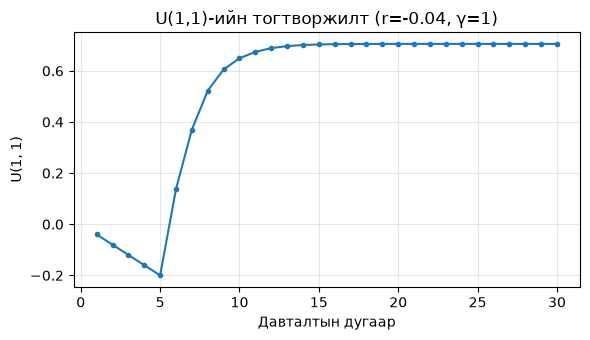

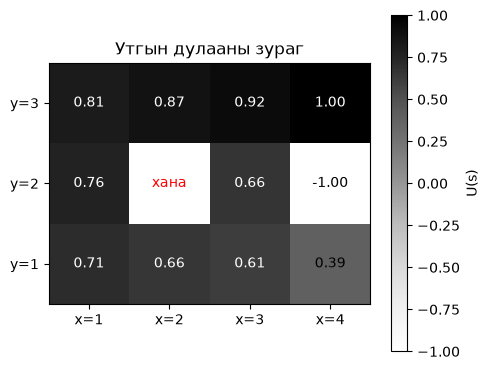

In [8]:
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(history) + 1), history, marker=".")
plt.xlabel("Давталтын дугаар")
plt.ylabel("U(1, 1)")
plt.title("U(1,1)-ийн тогтворжилт (r=-0.04, γ=1)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig_history.png", dpi=150)


def value_grid(U):
    g = np.full((H, W), np.nan)
    for (x, y), v in U.items():
        g[H - y, x - 1] = v  # y = 3 мөр эхэнд
    return g


g = value_grid(U)
plt.figure(figsize=(5, 3.8))
plt.imshow(g, cmap="Greys")
plt.colorbar(label="U(s)")
for y in range(H):
    for x in range(W):
        if not np.isnan(g[y, x]):
            v = g[y, x]
            plt.text(x, y, f"{v:.2f}", ha="center", va="center",
                     color="white" if v > 0.6 else "black")
        else:
            plt.text(x, y, "хана", ha="center", va="center", color="red")
plt.xticks(range(W), [f"x={i}" for i in range(1, W + 1)])
plt.yticks(range(H), [f"y={i}" for i in range(H, 0, -1)])
plt.title("Утгын дулааны зураг")
plt.tight_layout()
plt.savefig("fig_heatmap.png", dpi=150)

U9, it9, _ = value_iteration(gamma=0.9)
print("γ=0.9: давталт =", it9, " U(1,1) =", round(U9[(1, 1)], 3))
print_values(U9)
print_policy(extract_policy(U9))

## Нэмэлт 12.8: Гулгалтгүй ба эерэг шагналтай ертөнц

In [9]:
SLIPPERY = False
Ud, itd, _ = value_iteration()
print("Гулгалтгүй: U(1,1) =", round(Ud[(1, 1)], 3), " давталт =", itd)
print_policy(extract_policy(Ud))
SLIPPERY = True

Up, itp, hp = value_iteration(r=0.1, max_iter=200)
print("r=+0.1: давталт =", itp, " U(1,1) =", round(Up[(1, 1)], 2))
print("U(1,1) 50, 100, 200 дахь давталтад:", [round(hp[i - 1], 2) for i in (50, 100, 200)])
print_policy(extract_policy(Up))

Гулгалтгүй: U(1,1) = 0.8  давталт = 7
 →  →  → +1
 ↑  #  ↑ -1
 ↑  →  ↑  ←
r=+0.1: давталт = 200  U(1,1) = 20.68
U(1,1) 50, 100, 200 дахь давталтад: [5.68, 10.68, 20.68]
 ↑  ↑  ← +1
 ↑  #  ← -1
 ↑  ↑  ←  ↓
